<div style="background:linear-gradient(135deg,#58cc02,#1cb0f6);padding:28px;border-radius:14px;color:white;font-family:Segoe UI,Arial,sans-serif">
  <h1 style="margin:0;font-size:32px">🦉 Duolingo Learner Personas</h1>
  <p style="margin:6px 0 0;font-size:17px">Behavioral Segmentation with K-Means &amp; Gaussian Mixture Models</p>
</div>

<h2 style="color:#58a700">🎯 Aim</h2>
<p>Discover the distinct types of learners using the app, turn each segment into an actionable
persona, and recommend a targeted product action and test metric for each, so the growth team
can replace one-size-fits-all reminders with personalised nudges.</p>

<h2 style="color:#58a700">📦 Dataset Details</h2>
<table style="border-collapse:collapse;width:100%">
  <tr style="background:#58cc02;color:white"><th style="padding:8px;text-align:left">Item</th><th style="padding:8px;text-align:left">Detail</th></tr>
  <tr><td style="padding:8px;border:1px solid #ddd">Source</td><td style="padding:8px;border:1px solid #ddd">Duolingo-style learner activity dataset (StrataScratch project)</td></tr>
  <tr><td style="padding:8px;border:1px solid #ddd">Size</td><td style="padding:8px;border:1px solid #ddd">6,000 learners × 18 columns, last 90 days of activity</td></tr>
  <tr><td style="padding:8px;border:1px solid #ddd">Behavior features</td><td style="padding:8px;border:1px solid #ddd">Sessions/week, session length, XP, lessons, streak, weekend &amp; morning share, leaderboard, new-content share, recency</td></tr>
  <tr><td style="padding:8px;border:1px solid #ddd">Context columns</td><td style="padding:8px;border:1px solid #ddd">Country, platform, subscription, notifications, signup date, courses active</td></tr>
  <tr><td style="padding:8px;border:1px solid #ddd">Known issues</td><td style="padding:8px;border:1px solid #ddd">1.5% missing session length, heavy skew, implausible bot-like accounts</td></tr>
</table>

<h2 style="color:#58a700">🛠️ Methods</h2>
<p>EDA → anomaly detection → log + standard scaling → K-Means (elbow + silhouette) →
Gaussian Mixture comparison → persona profiling → product recommendations → Power BI dashboard.</p>

<h2 style="color:#58a700">📈 Deliverables</h2>
<ul>
  <li><code>clusters.csv</code> (learner_id, cluster) for all 6,000 learners</li>
  <li>Persona profiles with recommendations and test metrics</li>
  <li>Interactive Power BI dashboard</li>
</ul>

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 30)
RS = 42

df = pd.read_csv(r"D:\Python\Duolingo\learners.csv")

<div style="border:1px solid #e5e5e5;border-radius:12px;padding:18px 24px;font-family:Segoe UI,Arial,sans-serif">
  <h2 style="margin-top:0;color:#58a700">📑 Table of Contents</h2>
  <ol style="line-height:1.9;font-size:16px;margin:0">
    <li>Setup &amp; Data Loading</li>
    <li>Basic Exploration</li>
    <li>Data Preprocessing (Duplicates, Nulls, Outliers)</li>
    <li>Feature Engineering</li>
    <li>Exploratory Data Analysis</li>
    <li>Clustering: K-Means &amp; Gaussian Mixture</li>
    <li>Persona Profiling</li>
    <li>Recommendations</li>
    <li>Export &amp; Power BI Dashboard</li>
  </ol>
</div>

<div style="background:#58cc02;color:white;padding:16px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;margin-top:10px">
  <span style="font-size:13px;opacity:.85;letter-spacing:1px">SECTION 2</span>
  <h1 style="margin:2px 0 4px;font-size:28px">🔍 Basic Exploration</h1>
  <p style="margin:0;font-size:15px">Understand the structure, types and ranges of the data before changing anything.</p>
</div>

In [3]:
# Size and structure
print("Shape:", df.shape)
df.info()

Shape: (6000, 18)
<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   learner_id                 6000 non-null   str    
 1   signup_date                6000 non-null   str    
 2   country                    6000 non-null   str    
 3   platform                   6000 non-null   str    
 4   courses_active             6000 non-null   int64  
 5   subscription               6000 non-null   str    
 6   days_active_last_30        6000 non-null   int64  
 7   sessions_per_week          6000 non-null   float64
 8   avg_session_minutes        5907 non-null   float64
 9   longest_streak_days        6000 non-null   int64  
 10  lessons_completed_90d      6000 non-null   int64  
 11  xp_earned_90d              6000 non-null   int64  
 12  share_sessions_weekend     6000 non-null   float64
 13  share_sessions_morning     6000 non-null 

In [4]:
#First 5 rows
df.head()

,learner_id,signup_date,country,platform,courses_active,subscription,days_active_last_30,sessions_per_week,avg_session_minutes,longest_streak_days,lessons_completed_90d,xp_earned_90d,share_sessions_weekend,share_sessions_morning,leaderboard_weeks_joined,share_lessons_new_content,days_since_last_active,notifications_enabled
0,L100001,2025-06-13,United States,android,1,super,16,3.1,NaN,30,862,13039,0.39,0.66,7,0.16,0,yes
1,L100002,2024-07-13,India,android,2,free,11,1.3,7.9,29,236,4151,0.42,0.19,0,0.72,16,yes
2,L100003,2025-04-14,Mexico,android,2,free,14,4.4,111.7,7,152,2647,0.66,0.00,0,0.66,8,no
3,L100004,2024-01-22,Brazil,ios,1,super,30,8.7,23.4,133,548,11093,0.63,0.43,13,0.48,0,yes
4,L100005,2024-01-22,India,ios,1,free,6,6.6,87.0,3,86,1390,0.87,0.14,0,0.74,0,yes


In [5]:
# Last 5 rows
df.tail()

,learner_id,signup_date,country,platform,courses_active,subscription,days_active_last_30,sessions_per_week,avg_session_minutes,longest_streak_days,lessons_completed_90d,xp_earned_90d,share_sessions_weekend,share_sessions_morning,leaderboard_weeks_joined,share_lessons_new_content,days_since_last_active,notifications_enabled
5995,L105996,2023-05-04,France,android,3,super,6,2.0,13.9,7,38,599,0.96,0.00,0,0.68,71,no
5996,L105997,2024-09-03,United States,android,3,free,3,3.1,36.3,27,119,3013,0.17,0.29,3,0.88,51,yes
5997,L105998,2023-05-28,Brazil,android,1,free,0,4.3,28.8,8,395,6743,0.45,0.09,3,1.00,19,yes
5998,L105999,2023-07-25,United Kingdom,android,1,super,28,12.5,10.6,31,1563,27231,0.06,0.85,1,0.30,4,no
5999,L106000,2025-06-09,Germany,android,3,free,1,2.0,3.8,3,62,950,0.37,0.22,0,0.38,10,no


In [6]:
# 5 sample rows
df.sample(5)

,learner_id,signup_date,country,platform,courses_active,subscription,days_active_last_30,sessions_per_week,avg_session_minutes,longest_streak_days,lessons_completed_90d,xp_earned_90d,share_sessions_weekend,share_sessions_morning,leaderboard_weeks_joined,share_lessons_new_content,days_since_last_active,notifications_enabled
3523,L103524,2023-12-18,United States,android,1,free,24,10.2,67.8,88,132,2372,0.33,0.17,2,0.98,0,yes
3997,L103998,2023-11-18,United States,android,1,free,0,1.1,13.1,5,10,524,0.45,0.60,1,0.78,13,no
5971,L105972,2025-03-10,India,android,1,super,15,7.8,12.2,29,1172,19632,0.26,0.39,13,0.31,7,yes
4748,L104749,2025-02-25,Germany,android,1,free,14,5.8,2.9,353,89,2051,0.00,0.58,2,0.44,0,yes
4087,L104088,2023-06-28,Japan,ios,1,super,30,34.0,28.5,149,366,10547,0.56,0.32,11,0.68,0,yes


In [7]:
# Summary statistics for numbers
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
courses_active,6000.0,1.36,0.61,1.0,1.00,1.00,2.00,3.0
days_active_last_30,6000.0,13.97,10.70,0.0,4.00,13.00,24.00,30.0
sessions_per_week,6000.0,8.18,15.47,0.1,1.50,3.70,9.20,232.7
avg_session_minutes,5907.0,24.46,36.46,1.0,4.90,11.20,29.80,564.0
longest_streak_days,6000.0,109.71,212.39,1.0,4.00,14.00,127.25,3169.0
lessons_completed_90d,6000.0,347.38,687.21,1.0,42.00,146.00,370.00,10151.0
xp_earned_90d,6000.0,6282.68,11686.83,14.0,1191.75,3025.00,6695.50,150369.0
share_sessions_weekend,6000.0,0.41,0.26,0.0,0.21,0.38,0.58,1.0
share_sessions_morning,6000.0,0.43,0.25,0.0,0.25,0.43,0.61,1.0
leaderboard_weeks_joined,6000.0,3.43,3.88,0.0,0.00,2.00,6.00,13.0


In [8]:
# Summary for text columns
df.select_dtypes(exclude=["number", "datetime"]).describe().T

,count,unique,top,freq
learner_id,6000,6000,L100001,1
signup_date,6000,898,2023-03-17,17
country,6000,8,United States,1777
platform,6000,3,android,3163
subscription,6000,2,free,4947
notifications_enabled,6000,2,yes,3836


In [9]:
# Unique values in the category columns
for col in ["country", "platform", "subscription", "notifications_enabled", "courses_active"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False), "\n")

--- country ---
country
United States     1777
India             1064
Brazil             724
Mexico             615
France             515
Germany            497
Japan              414
United Kingdom     394
Name: count, dtype: int64 

--- platform ---
platform
android    3163
ios        2226
web         611
Name: count, dtype: int64 

--- subscription ---
subscription
free     4947
super    1053
Name: count, dtype: int64 

--- notifications_enabled ---
notifications_enabled
yes    3836
no     2164
Name: count, dtype: int64 

--- courses_active ---
courses_active
1    4227
2    1357
3     416
Name: count, dtype: int64 



<div style="background:#f0fbe6;border-left:5px solid #58cc02;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>💡 Observations:</b>
  <ul>
    <li>Dataset has <b>6,000 rows × 18 columns</b> (12 numeric, 5 text, 1 date).</li>
    <li>Only <code>avg_session_minutes</code> shows missing values.</li>
    <li>Platform has 3 values, subscription 2, country 8 (as United States on Top).</li>
    <li>Max values of <code>xp_earned_90d</code>, <code>sessions_per_week</code> and <code>longest_streak_days</code> are far above their means, which suggests skew and unusual accounts.</li>
  </ul>
</div>

<div style="background:#58cc02;color:white;padding:16px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;margin-top:10px">
  <span style="font-size:13px;opacity:.85;letter-spacing:1px">SECTION 3</span>
  <h1 style="margin:2px 0 4px;font-size:28px">🧹 Data Preprocessing</h1>
  <p style="margin:0;font-size:15px">Handle duplicates, missing values and unusual accounts.</p>
</div>

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">3.1 Duplicate Check</h3>

In [10]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate learner IDs:", df["learner_id"].duplicated().sum())

Fully duplicated rows: 0
Duplicate learner IDs: 0


<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">3.2 Missing Values</h3>

In [11]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "percent": missing_pct})[missing > 0]

,missing,percent
avg_session_minutes,93,1.55


In [12]:
# Do rows with missing session length differ from the rest?
df["session_min_missing"] = df["avg_session_minutes"].isna()
df.groupby("session_min_missing")[["sessions_per_week", "lessons_completed_90d", "xp_earned_90d"]].median().round(1)

,sessions_per_week,lessons_completed_90d,xp_earned_90d
session_min_missing,,,
False,3.7,146.0,3022.0
True,4.8,163.0,3255.0


<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">3.3 Outliers &amp; Unusual Accounts</h3>

In [13]:
cols = ["sessions_per_week", "avg_session_minutes", "lessons_completed_90d", "xp_earned_90d", "longest_streak_days"]
df[cols].quantile([.5, .9, .95, .99, .995, 1]).round(1)

,sessions_per_week,avg_session_minutes,lessons_completed_90d,xp_earned_90d,longest_streak_days
0.500,3.7,11.2,146.0,3025.0,14.0
0.900,18.1,60.3,791.1,13702.4,323.1
0.950,27.9,86.5,1296.1,21889.5,520.0
0.990,65.7,173.4,3129.2,52723.4,989.0
0.995,129.4,222.4,5103.1,95053.8,1243.0
1.000,232.7,564.0,10151.0,150369.0,3169.0


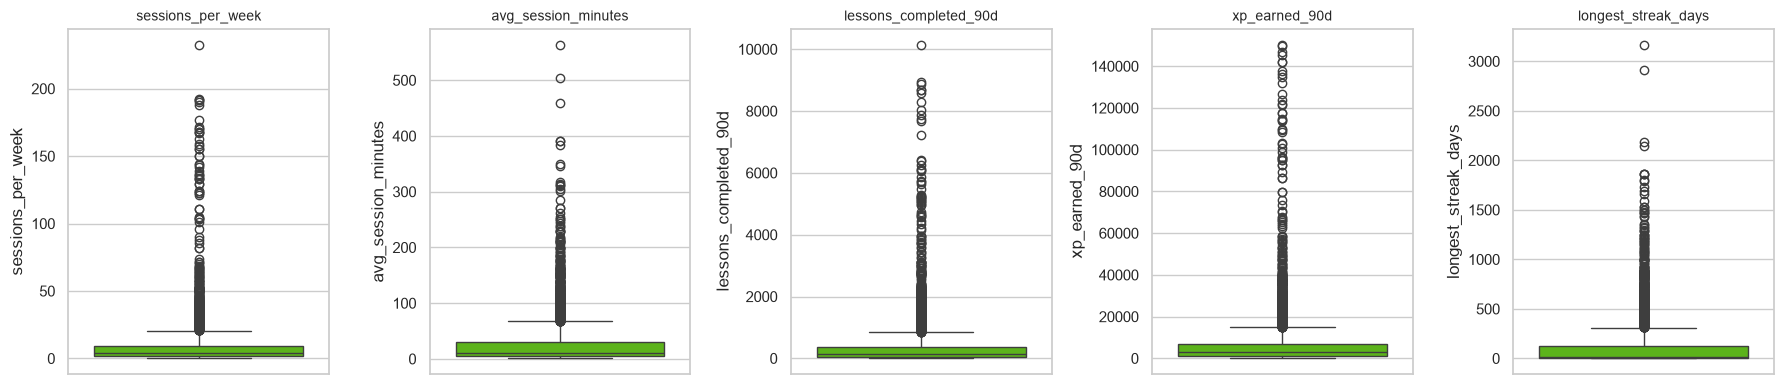

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(y=df[c], ax=ax, color="#58cc02")
    ax.set_title(c, fontsize=10)
plt.tight_layout()

In [15]:
#rules a person can defend
df["flag_too_many_sessions"] = df["sessions_per_week"] > 50      # more than 7 sessions per day, every day
df["flag_too_long_sessions"] = df["avg_session_minutes"] > 180   # average session over 3 hours
df["is_unusual"] = df[["flag_too_many_sessions", "flag_too_long_sessions"]].any(axis=1)

print(df[["flag_too_many_sessions", "flag_too_long_sessions", "is_unusual"]].sum())

flag_too_many_sessions    102
flag_too_long_sessions     53
is_unusual                155
dtype: int64


In [16]:
# confirm they look different from normal learners
df.groupby("is_unusual")[["sessions_per_week", "avg_session_minutes", "xp_earned_90d"]].median().round(1)

,sessions_per_week,avg_session_minutes,xp_earned_90d
is_unusual,,,
False,3.6,11.0,2967.0
True,56.8,28.1,8663.0


<div style="background:#fff8e6;border-left:5px solid #ff9600;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>⚙️ Decision:</b> Flagged accounts with more than 50 sessions/week or average sessions longer than 3 hours as unusual.
  They are <b>kept in the dataset but excluded from clustering</b>, because a few extreme points pull k-means centers toward them.
  They receive their own label (-1) in <code>clusters.csv</code>. Very high but plausible values (e.g. long streaks, high XP) are <b>not</b> removed; a log transform handles them in the next phase.
</div>

<div style="background:#58cc02;color:white;padding:16px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;margin-top:10px">
  <span style="font-size:13px;opacity:.85;letter-spacing:1px">SECTION 4</span>
  <h1 style="margin:2px 0 4px;font-size:28px">🛠️ Feature Engineering</h1>
  <p style="margin:0;font-size:15px">Impute, create features, transform skewed columns and scale.</p>
</div>

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">4.1 Separate Unusual Accounts</h3>

In [17]:
# Split off the unusual accounts
clean = df[~df["is_unusual"]].copy()
print("Learners to cluster:", len(clean))
print("Set aside:", df["is_unusual"].sum())

Learners to cluster: 5845
Set aside: 155


<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">4.2 Impute Missing Values</h3>

In [18]:
#Fill missing values (median of the clean data only)
median_min = clean["avg_session_minutes"].median()
clean["avg_session_minutes"] = clean["avg_session_minutes"].fillna(median_min)

print("Median used:", round(median_min, 2))
print("Remaining nulls:", clean.isna().sum().sum())

Median used: 11.05
Remaining nulls: 0


<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">4.3 Derived Features</h3>

In [19]:
# changed str to date
df["signup_date"] = pd.to_datetime(df["signup_date"])

In [20]:
clean["signup_date"] = pd.to_datetime(clean["signup_date"])
snapshot = df["signup_date"].max()
print(df["signup_date"].dtype)
print(clean["signup_date"].dtype)    # should now be datetime64, not str
print(snapshot)                      

datetime64[us]
datetime64[us]
2025-06-19 00:00:00


In [21]:
clean["account_age_days"]   = (snapshot - clean["signup_date"]).dt.days
clean["weekly_minutes"]     = clean["sessions_per_week"] * clean["avg_session_minutes"]
clean["xp_per_lesson"]      = clean["xp_earned_90d"] / clean["lessons_completed_90d"]
clean["lessons_per_active_day"] = clean["lessons_completed_90d"] / 90
clean["is_super"]           = (clean["subscription"] == "super").astype(int)
clean["notif_on"]           = (clean["notifications_enabled"] == "yes").astype(int)

clean[["account_age_days", "weekly_minutes", "xp_per_lesson", "lessons_per_active_day"]].describe().round(1)

,account_age_days,weekly_minutes,xp_per_lesson,lessons_per_active_day
count,5845.0,5845.0,5845.0,5845.0
mean,449.9,135.4,31.2,3.5
std,259.3,270.3,71.6,5.9
min,0.0,0.1,12.0,0.0
25%,226.0,12.8,15.3,0.4
50%,448.0,48.4,17.7,1.6
75%,671.0,142.0,24.0,4.0
max,900.0,6399.2,2448.5,112.8


<div style="background:#fff8e6;border-left:5px solid #ff9600;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>⚙️ Decision:</b> Derived features are used to <b>describe</b> personas and in the dashboard, but clustering uses the 11 original behavior columns.
  The derived ones are built from those same columns, so adding them would double-count information and distort the distances.
  Context columns (country, platform, subscription) describe who the learners are, not how they behave, so they are also kept out of the clustering.
</div>

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">4.4 Transform Skewed Columns</h3>

In [22]:
BEH = ["days_active_last_30", "sessions_per_week", "avg_session_minutes", "longest_streak_days",
       "lessons_completed_90d", "xp_earned_90d", "share_sessions_weekend", "share_sessions_morning",
       "leaderboard_weeks_joined", "share_lessons_new_content", "days_since_last_active"]

skew_before = clean[BEH].skew().round(2)
skewed_cols = skew_before[skew_before > 1].index.tolist()
print("Columns to log-transform:", skewed_cols)

X = clean[BEH].copy()
X[skewed_cols] = np.log1p(X[skewed_cols])
skew_after = X.skew().round(2)

pd.DataFrame({"before": skew_before, "after": skew_after})

Columns to log-transform: ['sessions_per_week', 'avg_session_minutes', 'longest_streak_days', 'lessons_completed_90d', 'xp_earned_90d', 'leaderboard_weeks_joined', 'days_since_last_active']


,before,after
days_active_last_30,0.18,0.18
sessions_per_week,2.25,0.40
avg_session_minutes,2.41,0.30
longest_streak_days,4.13,0.36
lessons_completed_90d,5.50,-0.25
xp_earned_90d,5.02,-0.50
share_sessions_weekend,0.45,0.45
share_sessions_morning,0.16,0.16
leaderboard_weeks_joined,1.06,0.13
share_lessons_new_content,-0.16,-0.16


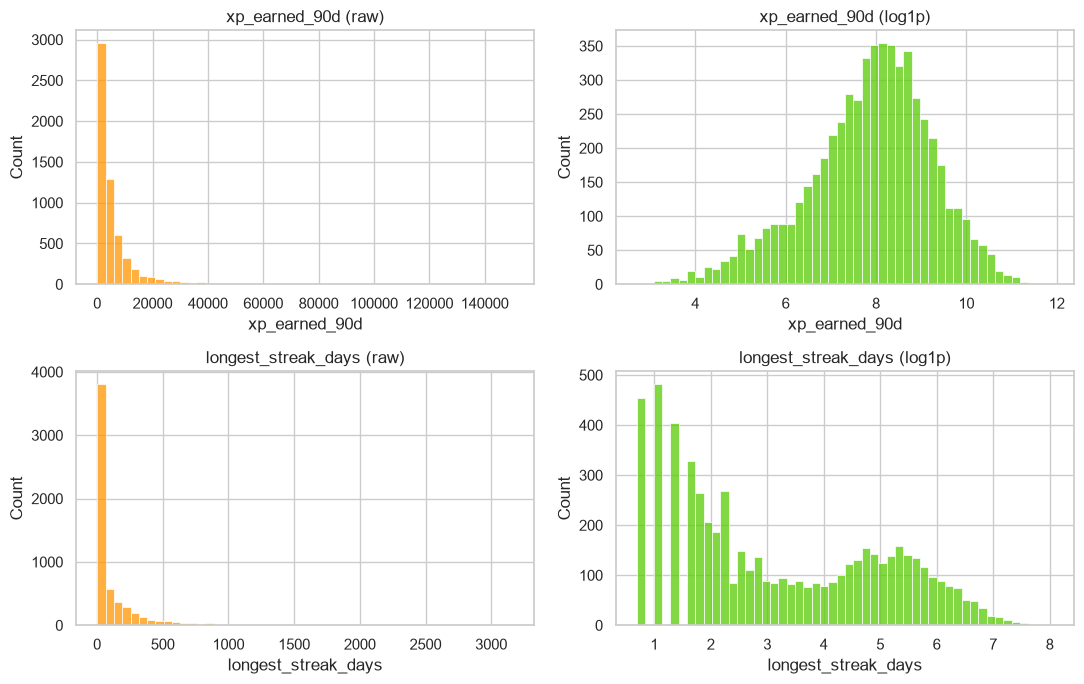

In [23]:
# before vs after for the two most skewed columns
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, c in enumerate(["xp_earned_90d", "longest_streak_days"]):
    sns.histplot(clean[c], bins=50, ax=axes[i, 0], color="#ff9600").set_title(f"{c} (raw)")
    sns.histplot(X[c], bins=50, ax=axes[i, 1], color="#58cc02").set_title(f"{c} (log1p)")
plt.tight_layout()

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">4.5 Feature Scaling</h3>

In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xs = scaler.fit_transform(X)

print("Shape:", Xs.shape)
print("Means (≈0):", Xs.mean(axis=0).round(2))
print("Std   (≈1):", Xs.std(axis=0).round(2))

Shape: (5845, 11)
Means (≈0): [-0. -0.  0.  0.  0. -0. -0. -0.  0. -0.  0.]
Std   (≈1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


<div style="background:#fff8e6;border-left:5px solid #ff9600;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>⚙️ Decision:</b> Applied <code>log1p</code> to columns with skew &gt; 1 (volume and recency metrics) to reduce the influence of long tails,
  then standardized all 11 behavior features. K-means uses Euclidean distance, so without scaling, columns measured in thousands would dominate the clusters.
</div>

<div style="background:#58cc02;color:white;padding:16px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;margin-top:10px">
  <span style="font-size:13px;opacity:.85;letter-spacing:1px">SECTION 5</span>
  <h1 style="margin:2px 0 4px;font-size:28px">📊 Exploratory Data Analysis</h1>
  <p style="margin:0;font-size:15px">Find patterns in distributions, correlations and learner groups before clustering.</p>
</div>

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">5.1 Feature Distributions</h3>

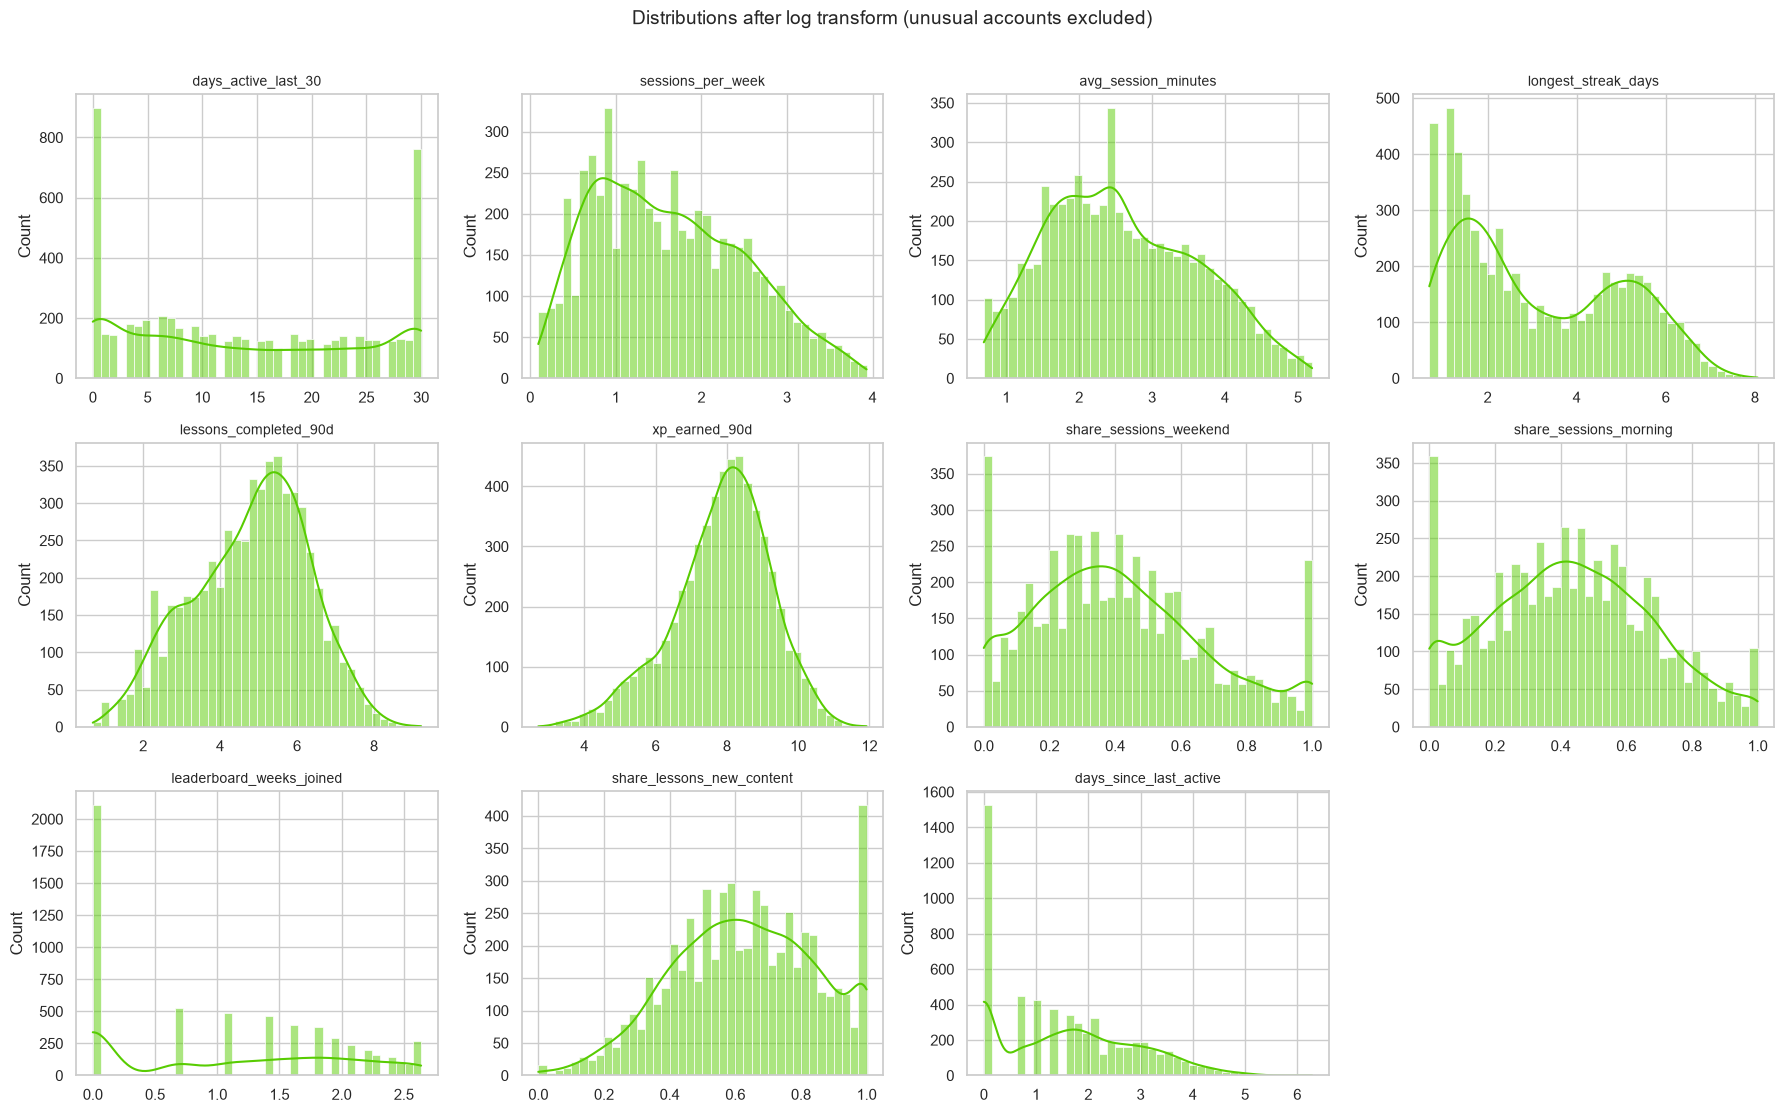

In [25]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.flat, BEH):
    sns.histplot(X[c], bins=40, kde=True, ax=ax, color="#58cc02")
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
for ax in axes.flat[len(BEH):]:
    ax.axis("off")
plt.suptitle("Distributions after log transform (unusual accounts excluded)", y=1.01, fontsize=14)
plt.tight_layout()

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">5.2 Correlations</h3>

Text(0.5, 1.0, 'Correlation of behavior features (log-transformed)')

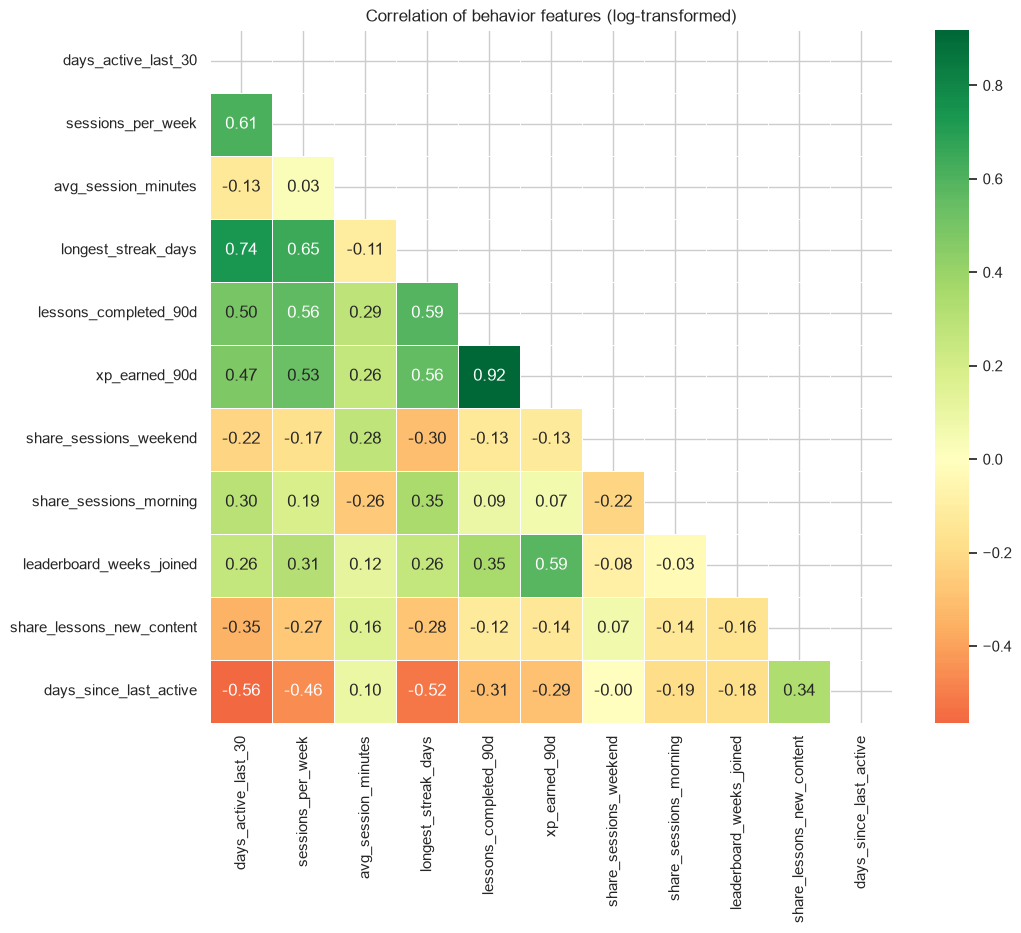

In [26]:
plt.figure(figsize=(11, 9))
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdYlGn", center=0, linewidths=.5)
plt.title("Correlation of behavior features (log-transformed)")

<div style="background:#f0fbe6;border-left:5px solid #58cc02;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>💡 Insights:</b>
  <ul>
    <li>Activity volume metrics (lessons, XP, streak, sessions, active days) move together; lessons and XP are nearly redundant (r = 0.92).</li>
    <li>Recency is negatively correlated with every engagement metric: recently active learners are the heavy users.</li>
    <li>Timing behavior is a separate axis: morning learners are consistent (higher streaks), weekend learners have longer sessions but shorter streaks.</li>
    <li>Platform has almost no effect on engagement, so it will not drive the segments.</li>
  </ul>
</div>

<div style="background:#fff8e6;border-left:5px solid #ff9600;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>⚙️ Decision to test:</b> Lessons and XP are almost duplicates (r ≈ 0.92), so together they give "activity volume" double weight in k-means.
  We will cluster once with all 11 features and once with <code>xp_earned_90d</code> removed, then compare the results.
</div>

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">5.3 Who Are the Learners?</h3>

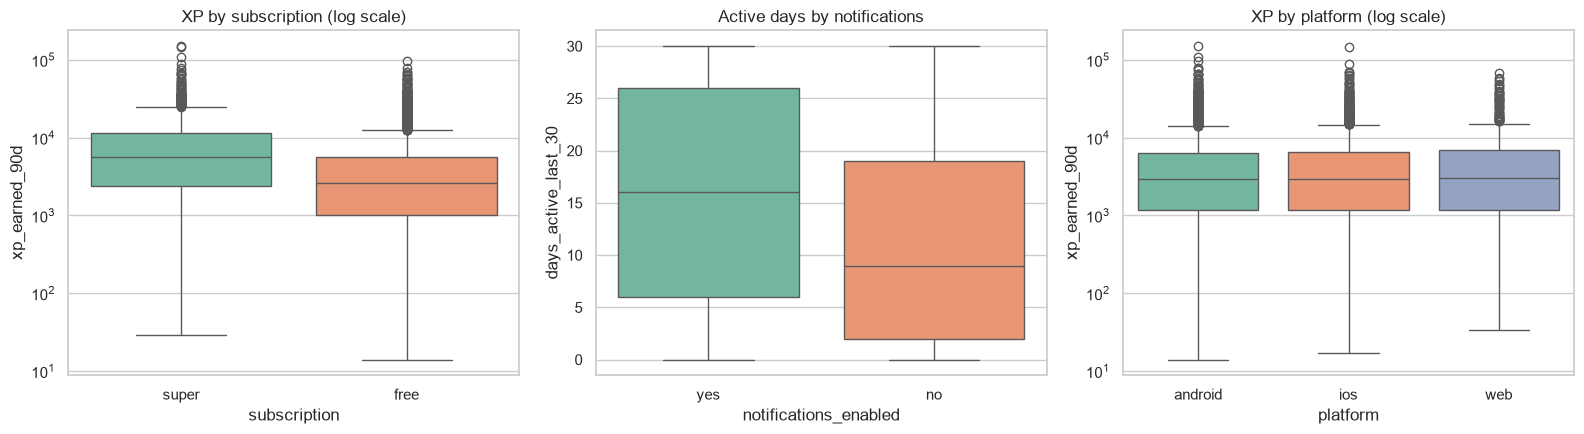

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=clean, x="subscription", y="xp_earned_90d", ax=axes[0], palette="Set2", hue="subscription", legend=False)
axes[0].set_yscale("log"); axes[0].set_title("XP by subscription (log scale)")
sns.boxplot(data=clean, x="notifications_enabled", y="days_active_last_30", ax=axes[1], palette="Set2", hue="notifications_enabled", legend=False)
axes[1].set_title("Active days by notifications")
sns.boxplot(data=clean, x="platform", y="xp_earned_90d", ax=axes[2], palette="Set2", hue="platform", legend=False)
axes[2].set_yscale("log"); axes[2].set_title("XP by platform (log scale)")
plt.tight_layout()

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">5.4 Country &amp; Signup Trend</h3>

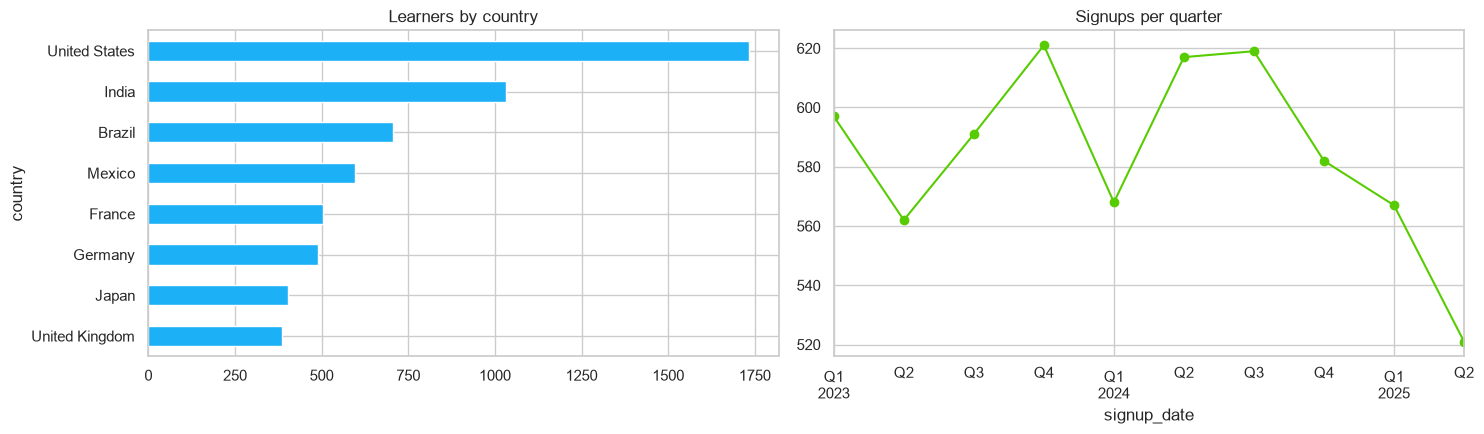

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
clean["country"].value_counts().plot(kind="barh", ax=axes[0], color="#1cb0f6").invert_yaxis()
axes[0].set_title("Learners by country")
clean.set_index("signup_date").resample("QS").size().plot(ax=axes[1], marker="o", color="#58cc02")
axes[1].set_title("Signups per quarter")
plt.tight_layout()

<div style="background:#f0fbe6;border-left:5px solid #58cc02;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>💡 Insight:</b> Super subscribers are about twice as active as free users (22 vs 10 active days), so engagement and subscription are strongly linked.
</div>

<div style="background:#58cc02;color:white;padding:16px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;margin-top:10px">
  <span style="font-size:13px;opacity:.85;letter-spacing:1px">SECTION 6</span>
  <h1 style="margin:2px 0 4px;font-size:28px">🤖 Clustering</h1>
  <p style="margin:0;font-size:15px">Segment learners with K-Means and compare with a second method.</p>
</div>

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">6.1 Two Feature Sets</h3>

In [30]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Set A: all 11 features (already scaled earlier)
XsA = Xs

# Set B: without xp_earned_90d (near-duplicate of lessons_completed_90d)
BEH_B = [c for c in BEH if c != "xp_earned_90d"]
XsB = StandardScaler().fit_transform(X[BEH_B])

print(XsA.shape, XsB.shape)

(5845, 11) (5845, 10)


<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">6.2 Choosing the Number of Clusters</h3>

,A: all 11 silhouette,B: no XP silhouette
2,0.298,0.300
3,0.259,0.253
4,0.206,0.256
5,0.212,0.206
6,0.188,0.187
7,0.166,0.158
8,0.152,0.150
9,0.141,0.138
10,0.132,0.129


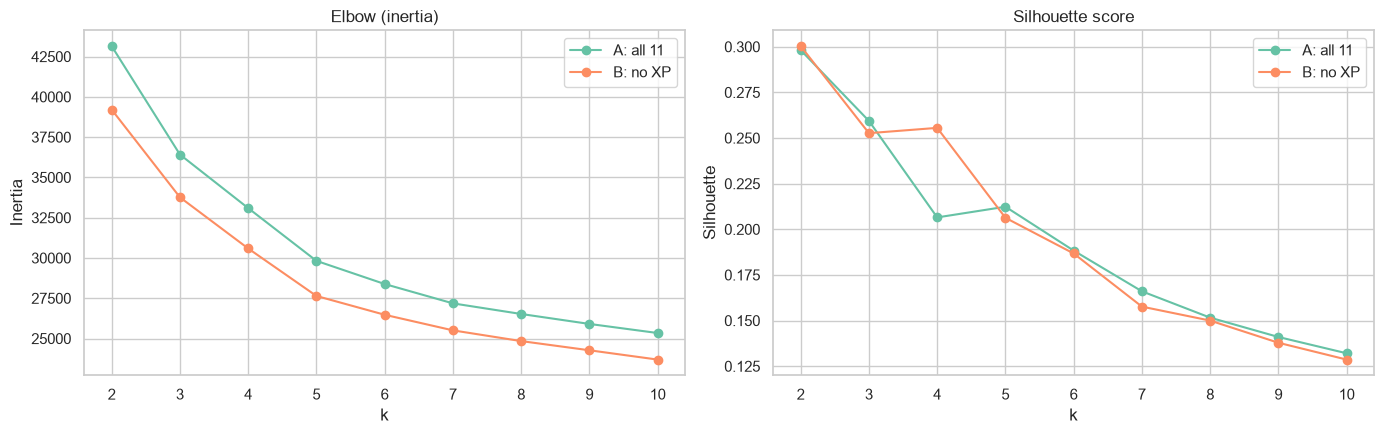

In [31]:
ks = range(2, 11)
results = {}
for name, M in {"A: all 11": XsA, "B: no XP": XsB}.items():
    inertia, sil = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=20, random_state=RS).fit(M)
        inertia.append(km.inertia_)
        sil.append(silhouette_score(M, km.labels_))
    results[name] = (inertia, sil)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, (inertia, sil) in results.items():
    axes[0].plot(ks, inertia, "o-", label=name)
    axes[1].plot(ks, sil, "o-", label=name)
axes[0].set(title="Elbow (inertia)", xlabel="k", ylabel="Inertia"); axes[0].legend()
axes[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette"); axes[1].legend()
plt.tight_layout()

pd.DataFrame({f"{n} silhouette": s for n, (_, s) in results.items()}, index=list(ks)).round(3)

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">6.3 Fit and Compare k=4 vs k=5</h3>

In [32]:
from sklearn.metrics import adjusted_rand_score

# Stability check across seeds
for k in [4, 5, 6]:
    labs = [KMeans(k, n_init=10, random_state=s).fit_predict(XsA) for s in range(5)]
    stab = np.mean([adjusted_rand_score(labs[0], l) for l in labs[1:]])
    print(f"k={k}: seed stability (ARI) = {stab:.3f}")

# Fit the two candidates
clean["km4"] = KMeans(4, n_init=20, random_state=RS).fit_predict(XsA)
clean["km5"] = KMeans(5, n_init=20, random_state=RS).fit_predict(XsA)

print(clean["km4"].value_counts().sort_index().to_dict())
print(clean["km5"].value_counts().sort_index().to_dict())

k=4: seed stability (ARI) = 1.000
k=5: seed stability (ARI) = 0.999
k=6: seed stability (ARI) = 0.685
{0: 901, 1: 1654, 2: 1571, 3: 1719}
{0: 915, 1: 896, 2: 853, 3: 1610, 4: 1571}


,days_active_last_30,sessions_per_week,avg_session_minutes,longest_streak_days,lessons_completed_90d,xp_earned_90d,share_sessions_weekend,share_sessions_morning,leaderboard_weeks_joined,share_lessons_new_content,days_since_last_active
km5,,,,,,,,,,,
0,8.0,2.60,42.6,5.0,99.0,2214.0,0.82,0.23,1.0,0.68,3.0
1,25.0,12.85,17.8,112.0,681.0,12790.5,0.33,0.36,10.0,0.47,1.0
2,3.0,2.40,33.0,11.0,228.0,4329.0,0.32,0.36,2.0,0.87,29.0
3,5.0,1.20,5.1,3.0,18.0,621.0,0.39,0.40,0.0,0.64,10.0
4,26.0,8.20,6.3,205.0,232.0,4216.0,0.29,0.64,2.0,0.56,1.0


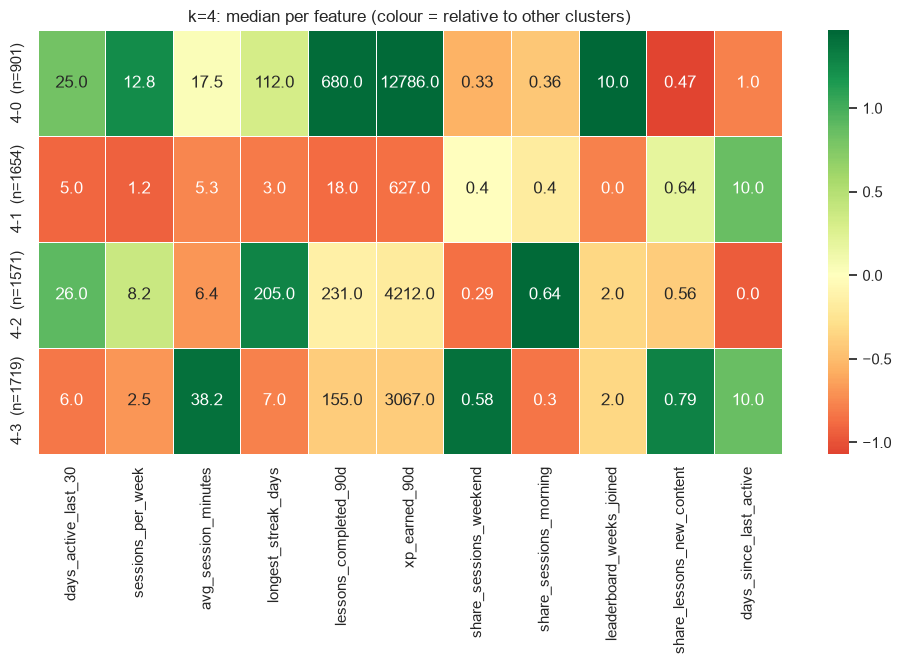

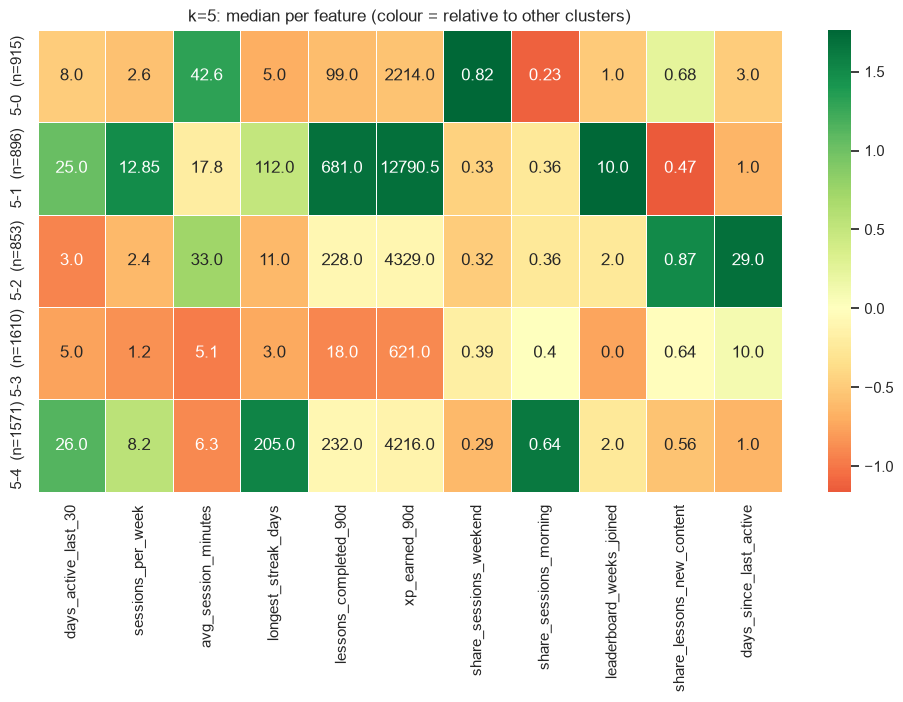

In [33]:
def profile_heatmap(col, title):
    med = clean.groupby(col)[BEH].median()
    z = (med - med.mean()) / med.std()
    z.index = [f"{col[-1]}-{i}  (n={n})" for i, n in zip(z.index, clean[col].value_counts().sort_index())]
    with sns.axes_style("white"):
        plt.figure(figsize=(12, 3.5 + 0.5 * len(z)))
        sns.heatmap(z, annot=med.round(2).values, fmt="", cmap="RdYlGn", center=0, linewidths=.5)
        plt.title(title)
    return med.round(2)

profile_heatmap("km4", "k=4: median per feature (colour = relative to other clusters)")
profile_heatmap("km5", "k=5: median per feature (colour = relative to other clusters)")

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">6.4 Final Model: k = 5</h3>

In [34]:
names = {0: "Weekend Warriors",
         1: "Leaderboard Power Users",
         2: "Cram & Vanish",
         3: "Casual Dabblers",
         4: "Morning Streakers"}

clean["cluster"] = clean["km5"]
clean["persona"] = clean["cluster"].map(names)

# Safety check: the names must match the behaviour (guards against IDs changing on a re-run)
med = clean.groupby("persona")[BEH].median()
assert med["share_sessions_weekend"].idxmax() == "Weekend Warriors"
assert med["share_sessions_morning"].idxmax() == "Morning Streakers"
assert med["days_since_last_active"].idxmax() == "Cram & Vanish"
assert med["xp_earned_90d"].idxmax() == "Leaderboard Power Users"
assert med["sessions_per_week"].idxmin() == "Casual Dabblers"
print("Persona names match the behaviour ✔")

Persona names match the behaviour ✔


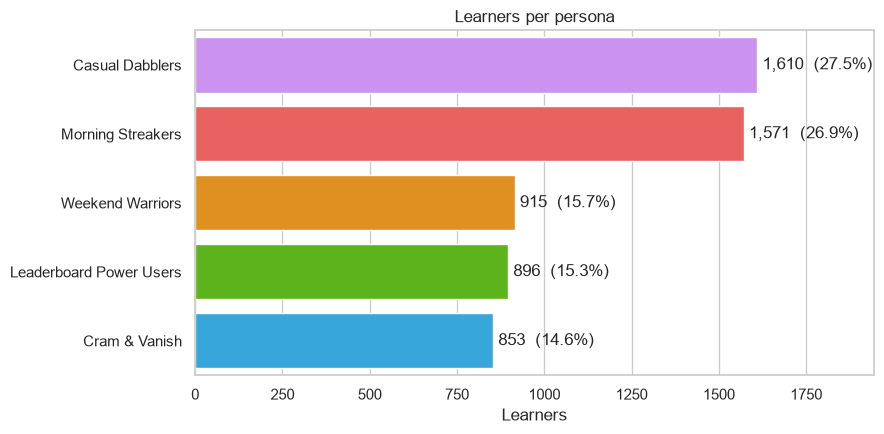

In [35]:
order = clean["persona"].value_counts().index
colors = ["#58cc02", "#1cb0f6", "#ff9600", "#ce82fe", "#ff4b4b"]

plt.figure(figsize=(9, 4.5))
ax = sns.countplot(data=clean, y="persona", order=order, palette=colors, hue="persona", legend=False)
for p in ax.patches:
    ax.text(p.get_width() + 15, p.get_y() + p.get_height()/2,
            f"{int(p.get_width()):,}  ({p.get_width()/len(clean)*100:.1f}%)", va="center")
ax.set(title="Learners per persona", xlabel="Learners", ylabel="")
ax.set_xlim(0, ax.get_xlim()[1] * 1.15)
plt.tight_layout()

In [36]:
profile = clean.groupby("persona").agg(
    learners=("learner_id", "count"),
    pct_super=("is_super", lambda s: round(s.mean() * 100, 1)),
    pct_notifications_on=("notif_on", lambda s: round(s.mean() * 100, 1)),
    median_active_days=("days_active_last_30", "median"),
    median_sessions_wk=("sessions_per_week", "median"),
    median_xp=("xp_earned_90d", "median"),
).sort_values("learners", ascending=False)
profile["pct_of_learners"] = (profile["learners"] / len(clean) * 100).round(1)
profile

,learners,pct_super,pct_notifications_on,median_active_days,median_sessions_wk,median_xp,pct_of_learners
persona,,,,,,,
Casual Dabblers,1610,7.5,34.5,5.0,1.20,621.0,27.5
Morning Streakers,1571,24.5,76.3,26.0,8.20,4216.0,26.9
Weekend Warriors,915,7.8,75.6,8.0,2.60,2214.0,15.7
Leaderboard Power Users,896,41.7,73.2,25.0,12.85,12790.5,15.3
Cram & Vanish,853,8.6,72.3,3.0,2.40,4329.0,14.6


<div style="background:#fff8e6;border-left:5px solid #ff9600;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>⚙️ Decision:</b> Chose <b>k = 5</b>. Silhouette scores are low across all k (≈0.21 at k=5), which is typical for overlapping behavioral groups, so the choice rests on several signals:
  the Gaussian-mixture BIC drops sharply at k=5, k-means is perfectly stable at k=5 (k=6 is not),
  and moving from k=4 to k=5 splits one broad group into two behaviorally distinct personas (weekend bingers and lapsed crammers) that need different product actions.
</div>

<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">6.5 Comparing K-Means with Hierarchical Clustering and Gaussian Mixture</h3>

In [37]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score

km_lab = clean["km5"].values
hc_lab = AgglomerativeClustering(n_clusters=5, linkage="ward").fit_predict(XsA)

gmm = {}
for ct in ["full", "tied", "diag", "spherical"]:
    g = GaussianMixture(5, covariance_type=ct, n_init=5, random_state=RS).fit(XsA)
    gmm[ct] = (g, g.predict(XsA))

rows = [("K-Means", km_lab, None), ("Hierarchical (Ward)", hc_lab, None)]
rows += [(f"GMM ({ct})", lab, g.bic(XsA)) for ct, (g, lab) in gmm.items()]

comp = pd.DataFrame({
    "method": [r[0] for r in rows],
    "silhouette": [round(silhouette_score(XsA, r[1]), 3) for r in rows],
    "agreement with K-Means (ARI)": [round(adjusted_rand_score(km_lab, r[1]), 3) for r in rows],
    "BIC": [None if r[2] is None else round(r[2]) for r in rows],
    "cluster sizes": [np.bincount(r[1]).tolist() for r in rows],
})
comp

,method,silhouette,agreement with K-Means (ARI),BIC,cluster sizes
0,K-Means,0.212,1.000,NaN,"[915, 896, 853, 1610, 1571]"
1,Hierarchical (Ward),0.191,0.793,NaN,"[1845, 951, 1612, 813, 624]"
2,GMM (full),0.034,0.292,105245.0,"[853, 1309, 1008, 2111, 564]"
3,GMM (tied),0.156,0.699,135503.0,"[473, 797, 1711, 1189, 1675]"
4,GMM (diag),0.131,0.562,129743.0,"[815, 741, 1047, 1539, 1703]"
5,GMM (spherical),0.214,0.930,151159.0,"[1664, 1683, 821, 875, 802]"


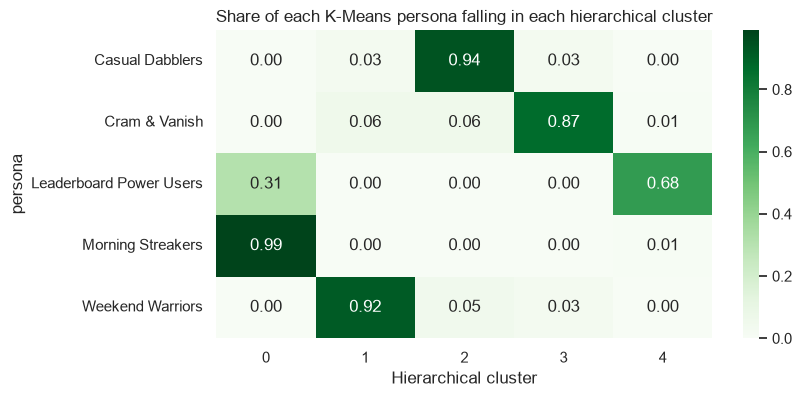

In [38]:
ct = pd.crosstab(clean["persona"], hc_lab)
ct_pct = ct.div(ct.sum(axis=1), axis=0).round(2)
with sns.axes_style("white"):
    plt.figure(figsize=(8, 4))
    sns.heatmap(ct_pct, annot=True, cmap="Greens", fmt=".2f")
    plt.title("Share of each K-Means persona falling in each hierarchical cluster")
    plt.xlabel("Hierarchical cluster")

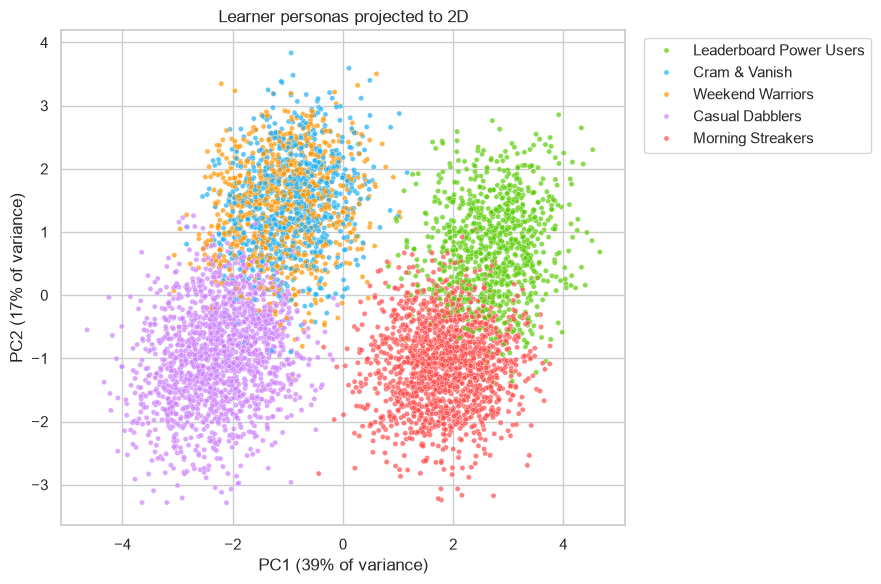

In [39]:
from sklearn.decomposition import PCA
pca = PCA(2, random_state=RS)
pc = pca.fit_transform(XsA)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=pc[:, 0], y=pc[:, 1], hue=clean["persona"], palette=colors, s=14, alpha=.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% of variance)")
plt.title("Learner personas projected to 2D"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

<div style="background:#fff8e6;border-left:5px solid #ff9600;padding:12px 16px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <b>⚙️ Decision:</b> Kept <b>K-Means (k=5)</b> as the final model. Hierarchical clustering reproduces most of the same groups (ARI ≈ 0.79), and a spherical GMM almost matches (ARI ≈ 0.93), so the segments are robust to method choice.
  A full-covariance GMM scored lowest on BIC but produced heavily overlapping components (silhouette ≈ 0.03) and uneven sizes, which are harder to turn into distinct, actionable personas.
  K-Means also gives the highest silhouette and perfect stability across seeds.
</div>

<div style="background:#58cc02;color:white;padding:16px 22px;border-radius:10px;font-family:Segoe UI,Arial,sans-serif;margin-top:10px">
  <span style="font-size:13px;opacity:.85;letter-spacing:1px">SECTION 7</span>
  <h1 style="margin:2px 0 4px;font-size:28px">💡 Personas &amp; Recommendations</h1>
  <p style="margin:0;font-size:15px">One product action and one test metric for each persona.</p>
</div>

<table style="border-collapse:collapse;width:100%;font-family:Segoe UI,Arial,sans-serif;font-size:14px">
<tr style="background:#58cc02;color:white;text-align:left">
  <th style="padding:10px">Persona</th><th style="padding:10px">Evidence from the data</th>
  <th style="padding:10px">Recommended action</th><th style="padding:10px">A/B test metric</th>
</tr>
<tr style="background:#f7fff0"><td style="padding:10px;border:1px solid #ddd"><b>🏆 Leaderboard Power Users</b><br>896 (15.3%)</td>
  <td style="padding:10px;border:1px solid #ddd">12.9 sessions/week, in the leaderboard 10 of 13 weeks. 41.7% already Super, so 58% are still free.</td>
  <td style="padding:10px;border:1px solid #ddd">Show the free users a Super trial offer tied to competition (for example, unlock a league perk after they finish in the top 3).</td>
  <td style="padding:10px;border:1px solid #ddd"><b>Free → Super conversion rate</b> within 30 days</td></tr>
<tr><td style="padding:10px;border:1px solid #ddd"><b>☀️ Morning Streakers</b><br>1,571 (26.9%)</td>
  <td style="padding:10px;border:1px solid #ddd">205-day median streak, 64% of sessions before noon, 76% have notifications on.</td>
  <td style="padding:10px;border:1px solid #ddd">Send the reminder in the early morning (about 7 to 8 am local) and offer a streak freeze to protect the habit.</td>
  <td style="padding:10px;border:1px solid #ddd"><b>90-day retention</b> (still active in days 60 to 90)</td></tr>
<tr style="background:#f7fff0"><td style="padding:10px;border:1px solid #ddd"><b>🎉 Weekend Warriors</b><br>915 (15.7%)</td>
  <td style="padding:10px;border:1px solid #ddd">82% of sessions on weekends, 43-minute sessions, only 7.8% Super.</td>
  <td style="padding:10px;border:1px solid #ddd">Saturday-morning push with a weekend Super trial. Long sessions benefit most from unlimited practice.</td>
  <td style="padding:10px;border:1px solid #ddd"><b>Trial start rate</b> (secondary: weekday sessions)</td></tr>
<tr><td style="padding:10px;border:1px solid #ddd"><b>✈️ Cram &amp; Vanish</b><br>853 (14.6%)</td>
  <td style="padding:10px;border:1px solid #ddd">Median 29 days since last active, but 228 lessons earlier and 87% new content. Notifications are on (72%) and not working.</td>
  <td style="padding:10px;border:1px solid #ddd">Win-back message after <b>7 days</b> of silence (not 29), with a short review lesson to ease them back in.</td>
  <td style="padding:10px;border:1px solid #ddd"><b>14-day reactivation rate</b></td></tr>
<tr style="background:#f7fff0"><td style="padding:10px;border:1px solid #ddd"><b>🌱 Casual Dabblers</b><br>1,610 (27.5%)</td>
  <td style="padding:10px;border:1px solid #ddd">1.2 sessions/week, 5-minute sessions, and only <b>34.5%</b> have notifications on (others 72 to 76%).</td>
  <td style="padding:10px;border:1px solid #ddd">Add an in-app prompt to turn on reminders, paired with a 5-minute daily goal.</td>
  <td style="padding:10px;border:1px solid #ddd"><b>Notification opt-in rate</b> (secondary: active days per month)</td></tr>
</table>

In [40]:
recs = pd.DataFrame([
    ["Leaderboard Power Users", "Competition-linked Super trial for free users", "Free → Super conversion (30d)"],
    ["Morning Streakers",       "Early-morning reminder + streak freeze",          "90-day retention"],
    ["Weekend Warriors",       "Saturday-morning weekend Super trial",            "Trial start rate"],
    ["Cram & Vanish",          "Day-7 win-back with a short review lesson",       "14-day reactivation rate"],
    ["Casual Dabblers",        "In-app prompt to enable reminders + 5-min goal",  "Notification opt-in rate"],
], columns=["persona", "recommended_action", "test_metric"])
recs

,persona,recommended_action,test_metric
0,Leaderboard Power Users,Competition-linked Super trial for free users,Free → Super conversion (30d)
1,Morning Streakers,Early-morning reminder + streak freeze,90-day retention
2,Weekend Warriors,Saturday-morning weekend Super trial,Trial start rate
3,Cram & Vanish,Day-7 win-back with a short review lesson,14-day reactivation rate
4,Casual Dabblers,In-app prompt to enable reminders + 5-min goal,Notification opt-in rate


<h3 style="color:#1cb0f6;border-left:5px solid #1cb0f6;padding-left:10px;font-family:Segoe UI,Arial,sans-serif">8.1 Save clusters.csv and the Power BI files</h3>

In [41]:
import os
os.makedirs("outputs", exist_ok=True)

# 1) The required file: every learner, unusual accounts labelled -1
out = df[["learner_id"]].copy()
out["cluster"] = -1
out.loc[clean.index, "cluster"] = clean["cluster"].values
out["cluster"] = out["cluster"].astype(int)
out.to_csv("outputs/clusters.csv", index=False)

# Validation checks
assert len(out) == 6000
assert out["learner_id"].is_unique
assert set(out["cluster"].unique()) == {-1, 0, 1, 2, 3, 4}
print(out["cluster"].value_counts().sort_index())

# 2) Rich file for Power BI
full = df.copy()
full["cluster"] = out["cluster"].values
full["persona"] = full["cluster"].map(names).fillna("Unusual Account")
full = full.join(clean[["account_age_days", "weekly_minutes", "xp_per_lesson"]])
for col in ["country", "platform", "subscription", "notifications_enabled"]:
    full[col] = full[col].astype(str)
full.to_csv("outputs/learners_clustered.csv", index=False)

# 3) Profile and recommendation tables
profile.to_csv("outputs/persona_profiles.csv")
recs.to_csv("outputs/persona_recommendations.csv", index=False)
print("Saved:", os.listdir("outputs"))

cluster
-1     155
 0     915
 1     896
 2     853
 3    1610
 4    1571
Name: count, dtype: int64
Saved: ['clusters.csv', 'learners_clustered.csv', 'persona_profiles.csv', 'persona_recommendations.csv']


<div style="background:linear-gradient(135deg,#58cc02,#1cb0f6);padding:22px;border-radius:12px;color:white;font-family:Segoe UI,Arial,sans-serif">
  <h2 style="margin:0 0 8px">✅ Conclusion</h2>
  <ul style="margin:0;line-height:1.8">
    <li>6,000 learners analysed; 155 bot-like or implausible accounts set aside (label -1).</li>
    <li>K-Means (k=5) found five stable personas; hierarchical clustering agrees (ARI 0.79).</li>
    <li>Casual Dabblers (27.5%) are hard to reach: only 34.5% have notifications on.</li>
    <li>Cram &amp; Vanish learners have reminders on but have been silent for about a month, so a day-7 win-back is recommended.</li>
    <li>Leaderboard Power Users are the best Super upsell target, with 58% still on the free plan.</li>
  </ul>
</div>

<div style="background:#fff0f0;border-left:5px solid #ff4b4b;padding:14px 18px;border-radius:6px;font-family:Segoe UI,Arial,sans-serif">
  <h3 style="margin:0 0 8px;color:#d33">⚠️ Limitations &amp; Next Steps</h3>
  <ul style="margin:0;line-height:1.8">
    <li><b>Overlapping groups:</b> silhouette scores are low across all values of k (about 0.21 at k=5). Learner behavior is a continuum, so personas describe tendencies and do not draw hard boundaries.</li>
    <li><b>Fuzzy boundary:</b> only 68% of Leaderboard Power Users fall into a single hierarchical cluster, and about 31% overlap with Morning Streakers. Both are highly consistent daily learners, separated mainly by volume and leaderboard activity.</li>
    <li><b>Model choice:</b> a full-covariance Gaussian mixture scored lowest on BIC but produced heavily overlapping, unevenly sized components (silhouette about 0.03), so K-Means was kept for interpretability.</li>
    <li><b>Unusual accounts:</b> 155 accounts (2.6%) were excluded using rule-based thresholds (more than 50 sessions/week or average sessions over 3 hours). The thresholds are judgment calls, and the accounts should be reviewed by a fraud or data-quality team.</li>
    <li><b>Correlation, not causation:</b> differences such as higher activity among learners with notifications on do not prove that notifications cause engagement. The recommendations need A/B tests before any rollout.</li>
    <li><b>Snapshot data:</b> the analysis covers a single 90-day window, so seasonality and persona changes over time are not captured.</li>
  </ul>
  <p style="margin:10px 0 0"><b>Next steps:</b> track how learners move between personas over time, run the five A/B tests, and re-cluster each quarter to check that the segments stay stable.</p>
</div>